# Case Study 24 — When Is a Phone Photo "Fit for Purpose"? Validating Computer-Vision Motor Inspections and Deciding Which Claims to Auto-Settle

**Priority:** ★ Optional · **Reference:** Case Study 24 — *ICICI Lombard: smartphone motor inspection with computer vision* (`indian_fintech_data_science_case_studies.md`)
**Audience:** Head of Motor Claims, Underwriting (break-in renewals), Claims Audit, Operations
**Data:** ⚠️ **SYNTHETIC** (D-24-01). We simulate a validation study's records (model outputs vs surveyor re-inspection), not images.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs24_motor_inspection_cv_validation.ipynb`

## 0. Executive Summary for Business

*(Synthetic validation records, not images: model probabilities vs a surveyor re-inspection sample. ICICI Lombard disclosed no accuracy figure beyond "fit for purpose". Written after the analysis.)*

- **The question:** can customer phone photos replace a surveyor, and for which cases?
- **The model is good at some things and weak at others (vs surveyors, 49,000 part assessments):**
  - **Cracks** (mostly glass and lamps): 92% found.
  - **Clean parts:** 96% correctly passed.
  - **Scratches:** 73% found, but only 47% of "scratch" calls are real scratches (many are glare or dents).
  - **Dents:** only **59% found**; 29% are called scratches. Dents drive repair cost, so this is the weak spot.
  - **Overall agreement with surveyors:** κ = 0.70 ("substantial").
- **Photo quality matters:** each +0.1 of quality cuts the odds of a wrong call by 20% (p ≈ 1e-22). A "retake your photo" prompt for the worst 5% of photos lifts accuracy on damaged parts from 74% to 75%, a small gain. Night shots are not the problem here (p = 0.8); blur and glare are.
- **Repair-cost estimates are too loose for settlement:** the model's case-level estimate is within ±₹3,000 of the surveyor's for only **55%** of cases (26% within ±15%). The 95% limits of agreement are ±₹10,000, and the error grows with claim size.
- **The pre-registered auto-settle rule almost works, but only on a sliver of claims:**
  - The best rule is "estimate ≤ ₹20,000, no structural dent predicted, every part confidence ≥ 0.7, photo quality ≥ 0.4".
  - It settles **5.4%** of own-damage claims with **0 complex claims found** in the sample. But with only ~147 checked, the one-sided 95% upper bound is **2.02%**, just above the 2% limit, so the rule is **not yet certified**. The rule of three says ~150 checked claims are needed even with zero errors, and several hundred more at a 0.5% true rate.
  - Looser rules cover up to 33% of claims but let complex claims through at 5–6% (upper bounds 6–8%).
- **Renewals (pre-existing damage) pass:** among break-in renewals that have damage, the model flags damage in **94.4%** (CI 92.2–96.0%), above the 90% target. Clean cars are passed correctly only 71% of the time, so some customers get unnecessary follow-up.
- **₹ at the documented 80,000 claims/month:** the rule auto-settles ≈ 4,300 claims, saving ≈ **₹0.65 crore/month** of surveyor visits (plus ≈ 11,000 customer-days of waiting) with no measured leakage. The documented target of "over 80,000 simple claims a month" is **not reachable on this accuracy** without a better dent model.
- **I recommend:**
  - Launch photo inspection for **renewals** now.
  - Auto-settle only the tight rule, with an extended validation of ≥ 600 checked claims to certify it.
  - Add a "second angle" photo prompt when a dent is possible.
  - Keep a random 20% surveyor sample for ongoing monitoring.

## 1. The Problem in Simple English

When a motor policy lapses and is renewed ("break-in"), or a customer claims for a small dent, an insurer traditionally sends a **surveyor**. That takes days and costs money. ICICI Lombard lets customers **upload phone photos** instead. A computer-vision model finds each car part and classifies damage (scratch, dent, crack), so simple cases can be settled the same day.

The model never has to be perfect. It has to be **"fit for purpose"**: good enough on the cases it decides alone, and smart enough to send the rest to a human. The data-science questions are:
- How accurate is it, part by part and damage type by damage type, against a surveyor?
- When do photos fail (blur, glare, night)?
- How close are its **repair-cost** estimates?
- Which claims can be **auto-settled** with an acceptable risk of paying a complex claim as simple?
- How big must the validation study be to prove it?

## 2. Reference from the Case File

### (a) What ICICI Lombard did — *documented*

| Item | Documented fact (quoted from the reference file) |
|---|---|
| Problem | Renewals after a break and simple damage claims needed physical inspections, taking "days or longer" |
| Question | "Can photos taken by the customer on a smartphone replace a surveyor's inspection?" |
| Approach | "Split uploaded images into frames" → "Identify car components" → "Detect damage types (scratch, dent, crack)" |
| Statistics / metrics | **ND**; accuracy "**fit for purpose**" (no figure); architecture ND; Microsoft Azure |
| Decision | Launched for renewals Dec 2018; claims module in beta in 2019; simple claims to be settled on app inspection |
| Impact | **150–200 cars a day** inspected through the app; inspection time "**days to mere minutes**"; target of "**over 80,000 simple claims every month**" by end-2019 with same-day turnaround |

**Source:** Microsoft customer story / press coverage (2018–19), links in the reference file.

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | 24,000 inspections (45% break-in renewals, 55% own-damage claims) × 10 parts = 240,000 part assessments. True damage, the model's probabilities for none/scratch/dent/crack, photo quality and night shots, and repair costs. A **20% surveyor re-inspection sample** (surveyors are 97% accurate). "Complex" = cost > ₹25,000 or a structural dent. |
| Statistics added | Per-class sensitivity/precision with Wilson CIs and Cohen's κ vs surveyor; logistic model of errors on photo quality; **Bland–Altman** agreement for cost estimates; a **triage rule** chosen by grid search with a **Clopper–Pearson upper bound** on complex claims wrongly auto-settled; renewal pre-existing-damage sensitivity; validation sample size (rule of three); ₹ |

### (c) How the industry uses this

AI photo inspection is now standard in Indian motor insurance: ICICI Lombard (InstaSpect), Bajaj Allianz, HDFC ERGO, Digit and Acko all use self-inspection, often with vendors such as Tractable or Inspektlabs. Banks use similar validation logic for AI document checks. IRDAI's push for faster claims settlement makes **"auto-settle simple, escalate complex"** the standard operating model, and the validation statistics here are what auditors and regulators expect.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | Which inspections and claims can be decided from photos alone, and how many surveyor visits does that save? |
| Analytical | What auto-settlement rule keeps the rate of complex claims wrongly auto-settled ≤ 2%, and repair-cost errors acceptable, while covering as many cases as possible? |

**Fit-for-purpose criteria (pre-registered, D-24-04):**
1. Among auto-settled claims, **≤ 2% are actually complex**, using the one-sided 95% Clopper–Pearson upper bound on the surveyor sample.
2. For auto-settled claims, the model's cost estimate is within **±₹3,000** of the surveyor's for ≥ 80% of claims.
3. For break-in renewals, pre-existing damage is detected (any damage flagged) with **≥ 90% sensitivity**, so it cannot be claimed later.

**Hypotheses**
- **H1:** H0: per-part accuracy does not depend on photo quality (logistic LR test).
- **H2:** H0: mean cost difference (model − surveyor) = 0 (paired t / Bland–Altman bias).

In [1]:
import sys, warnings, importlib, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.inter_rater import cohens_kappa

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public labelled car-damage images | Some exist (e.g., research datasets such as CarDD on GitHub, Kaggle car-damage sets), but **none come with insurer surveyor costs or Indian claim outcomes**, and training a CV model is outside the brief's library list. |
| **Decision** | Simulate the *validation records* (model probabilities vs surveyor truth), which is what the business decision depends on (D-24-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs24.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 24 (ICICI Lombard-style smartphone motor inspection with computer vision)
==============================================================================================================
THIS DATA IS SYNTHETIC. Inspection photos and claims data are confidential. We do NOT simulate images; we
simulate what a validation study records: per-part TRUE damage (from a surveyor re-inspection), the CV model's
predicted damage probabilities, photo quality, and repair-cost estimates.

Cases: customer self-inspections for (a) break-in policy renewals and (b) simple own-damage claims.
Parts: front_bumper, rear_bumper, bonnet, left_door, right_door, windshield, headlamp, tail_lamp, fender, mirror.
Damage classes: none / scratch / dent / crack (crack mainly glass and lamps).
Model accuracy depends on damage type (cracks on glass are easy, shallow dents are hard), photo quality
(blur, glare, night shots) and part. A claim is "simple" if total repair cost <= Rs 25,000 and no structural
part is dented; complex claims must go to a surveyor.

Calibration anchors (reference file, Case Study 24): "Split uploaded images into frames", "identify car
components", "detect damage types (scratch, dent, crack)"; accuracy "fit for purpose" (no figure);
150-200 cars a day; inspection time "days to mere minutes"; target ">80,000 simple claims every month".
Rates are our assumptions (decision.md D-24-02). Hidden truth columns start with "_".

Outputs: data/cs24/parts.csv.gz (case x part), data/cs24/cases.csv.gz
"""
import os
import numpy as np
import pandas as pd
from scipy.special import softmax

SEED = 42
PARTS = ["front_bumper", "rear_bumper", "bonnet", "left_door", "right_door", "windshield", "headlamp", "tail_lamp", "fender", "mirror"]
DMG = ["none", "scratch", "dent", "crack"]
COST = {"scratch": 2500, "dent": 6500, "crack": 9000}
PART_MULT = {"front_bumper": 1.0, "rear_bumper": 0.9, "bonnet": 1.6, "left_door": 1.3, "right_door": 1.3, "windshield": 1.5, "headlamp": 0.8, "tail_lamp": 0.5, "fender": 1.1, "mirror": 0.4}
GLASS = {"windshield", "headlamp", "tail_lamp", "mirror"}


def generate(seed=SEED, n=24_000):
    rng = np.random.default_rng(seed)
    kind = rng.choice(["renewal_breakin", "own_damage_claim"], n, p=[0.45, 0.55])
    quality = np.clip(rng.beta(5, 2, n), 0.05, 1)                                        # photo quality score (1 = sharp, well lit)
    night = (rng.random(n) < 0.12).astype(int); quality = np.where(night == 1, quality * 0.7, quality)
    car_value = np.round(np.exp(rng.normal(np.log(6e5), 0.5, n)), -3)
    rows = []
    for i in range(n):
        n_dmg = rng.poisson(0.3 if kind[i] == "renewal_breakin" else 1.6)
        hit = set(rng.choice(PARTS, min(n_dmg, len(PARTS)), replace=False)) if n_dmg else set()
        for p in PARTS:
            if p in hit:
                d = rng.choice(["scratch", "dent", "crack"], p=[0.15, 0.15, 0.70]) if p in GLASS else rng.choice(["scratch", "dent", "crack"], p=[0.55, 0.42, 0.03])
            else:
                d = "none"
            t = DMG.index(d)
            # model logits: correct class boosted by ease x quality; confusions scratch<->dent, none<->scratch
            ease = {"none": 3.2, "scratch": 1.9, "dent": 1.5, "crack": 2.6 if p in GLASS else 1.4}[d]
            lg = rng.normal(0, 0.9, 4); lg[t] += ease * (0.35 + 0.9 * quality[i])
            if d == "dent": lg[1] += 0.9
            if d == "scratch": lg[0] += 0.8
            if d == "none": lg[1] += 0.3 * (1 - quality[i]) * 3                              # glare looks like scratches
            pr = softmax(lg)
            cost = COST.get(d, 0) * PART_MULT[p] * np.exp(rng.normal(0, 0.25)) if d != "none" else 0.0
            rows.append((i, p, d, pr[0], pr[1], pr[2], pr[3], round(cost, -1)))
    parts = pd.DataFrame(rows, columns=["case_idx", "part", "_true_damage", "p_none", "p_scratch", "p_dent", "p_crack", "_true_cost"])
    parts["pred_damage"] = np.array(DMG)[parts[["p_none", "p_scratch", "p_dent", "p_crack"]].values.argmax(1)]
    # surveyor re-inspection on a validation sample (20% of cases): near-perfect but not perfect
    sv = rng.random(n) < 0.20
    parts["surveyor_checked"] = sv[parts.case_idx].astype(int)
    err = (rng.random(len(parts)) < 0.03) & (parts.surveyor_checked == 1)
    parts["surveyor_damage"] = np.where(parts.surveyor_checked == 1, np.where(err, np.where(parts._true_damage == "scratch", "dent", parts._true_damage), parts._true_damage), "")
    parts["surveyor_cost"] = np.where(parts.surveyor_checked == 1, np.round(parts._true_cost * np.exp(rng.normal(0, 0.08, len(parts))), -1), np.nan)
    # model cost estimate: expected cost under predicted probabilities, with its own error
    exp_cost = (parts.p_scratch * 2500 + parts.p_dent * 6500 + parts.p_crack * 9000) * parts.part.map(PART_MULT)
    parts["model_cost"] = np.round(np.where(parts.pred_damage == "none", 0, exp_cost * np.exp(rng.normal(0.05, 0.22, len(parts)))), -1)
    cases = parts.groupby("case_idx").agg(true_cost=("_true_cost", "sum"), model_cost=("model_cost", "sum"), surveyor_cost=("surveyor_cost", "sum"),
                                          n_true_damaged=("_true_damage", lambda s: (s != "none").sum()), structural_dent=("_true_damage", lambda s: 0)).reset_index()
    sd = parts[(parts._true_damage == "dent") & parts.part.isin(["bonnet", "left_door", "right_door", "fender"])].groupby("case_idx").size()
    cases["structural_dent"] = cases.case_idx.map(sd).fillna(0).gt(0).astype(int)
    cases["_complex"] = ((cases.true_cost > 25000) | (cases.structural_dent == 1)).astype(int)
    cases["case_id"] = [f"INS{i:06d}" for i in cases.case_idx]; cases["case_type"] = kind[cases.case_idx]; cases["photo_quality"] = quality[cases.case_idx].round(3)
    cases["night_shot"] = night[cases.case_idx]; cases["car_value_inr"] = car_value[cases.case_idx]; cases["surveyor_checked"] = sv[cases.case_idx].astype(int)
    cases.loc[cases.surveyor_checked == 0, "surveyor_cost"] = np.nan
    cases = cases.rename(columns={"true_cost": "_true_cost", "n_true_damaged": "_n_true_damaged"})
    parts.insert(0, "case_id", "INS" + parts.case_idx.astype(str).str.zfill(6))
    # data-quality defects
    parts = pd.concat([parts, parts.sample(n=500, random_state=seed)], ignore_index=True)                       # duplicate frames
    cases.loc[cases.sample(n=150, random_state=seed + 1).index, "photo_quality"] = np.nan                     # EXIF metadata missing
    return parts, cases


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs24"), exist_ok=True)
    p, c = generate(); p.to_csv(os.path.join(here, "cs24", "parts.csv.gz"), index=False); c.to_csv(os.path.join(here, "cs24", "cases.csv.gz"), index=False)
    pp = p.drop_duplicates(["case_id", "part"])
    print(len(c), "cases |", len(pp), "parts | part accuracy", (pp.pred_damage == pp._true_damage).mean().round(4), "| complex share", c._complex.mean().round(4))
    print(pd.crosstab(pp._true_damage, pp.pred_damage, normalize="index").round(3))

Overwriting data/generate_cs24.py


In [3]:
os.makedirs("data/cs24", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs24 as gen; importlib.reload(gen)
parts_raw, cases_raw = gen.generate(seed=SEED)
parts_raw.to_csv("data/cs24/parts.csv.gz", index=False); cases_raw.to_csv("data/cs24/cases.csv.gz", index=False)
print(f"{len(parts_raw):,} part rows | {len(cases_raw):,} cases")
parts_raw.drop(columns=["_true_damage", "_true_cost"]).sample(3, random_state=SEED).T

240,500 part rows | 24,000 cases


,225987,170654,198306
case_id,INS022598,INS017065,INS019830
case_idx,22598,17065,19830
part,tail_lamp,right_door,headlamp
p_none,0.6172,0.8106,0.9875
p_scratch,0.0430,0.0474,0.0042
p_dent,0.0633,0.0986,0.0064
p_crack,0.2765,0.0434,0.0018
pred_damage,none,none,none
surveyor_checked,0,1,0
surveyor_damage,,none,


| Parameter | Value | Basis |
|---|---|---|
| Inspections | 24,000: 45% break-in renewals (few damages), 55% own-damage claims (≈ 1.6 damaged parts) | **Documented** use cases |
| Parts × damage | 10 parts; glass/lamps mostly cracks; body panels scratches and dents | **Documented** damage types |
| Model behaviour | Cracks on glass easy; dents often confused with scratches; glare creates false scratches; accuracy rises with photo quality; 12% night shots | Typical CV failure modes |
| Costs | Scratch ₹2.5k, dent ₹6.5k, crack ₹9k × part multiplier (bonnet 1.6, mirror 0.4); "complex" = > ₹25k or structural dent | Our assumption |
| Surveyor sample | 20% of cases re-inspected; surveyors 97% accurate on damage class, ±8% on cost | Our design |
| DQ issues | 500 duplicate frames; 150 cases missing photo metadata (EXIF) | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("parts: case_id, part", "Inspection and car part"), ("p_none, p_scratch, p_dent, p_crack, pred_damage", "Model probabilities and predicted class"),
    ("model_cost", "Model's repair-cost estimate for the part"), ("surveyor_checked, surveyor_damage, surveyor_cost", "Surveyor re-inspection (20% of cases)"),
    ("_true_damage, _true_cost", "HIDDEN truth"), ("cases: case_type, photo_quality, night_shot, car_value_inr", "Inspection context (quality 0–1; 150 missing)"),
    ("model_cost, surveyor_cost (case level)", "Summed estimates"), ("_complex, _true_cost, structural_dent", "HIDDEN: complex claim flag and true cost"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs24/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"parts: case_id, part",Inspection and car part
1,"p_none, p_scratch, p_dent, p_crack, pred_damage",Model probabilities and predicted class
2,model_cost,Model's repair-cost estimate for the part
3,"surveyor_checked, surveyor_damage, surveyor_cost",Surveyor re-inspection (20% of cases)
4,"_true_damage, _true_cost",HIDDEN truth
5,"cases: case_type, photo_quality, night_shot, c...",Inspection context (quality 0–1; 150 missing)
6,"model_cost, surveyor_cost (case level)",Summed estimates
7,"_complex, _true_cost, structural_dent",HIDDEN: complex claim flag and true cost


## 5. Data Quality Checks

In [5]:
checks = {"duplicate case-part rows (repeated frames)": int(parts_raw.duplicated(["case_id", "part"]).sum()), "cases missing photo quality (EXIF)": int(cases_raw.photo_quality.isna().sum()),
          "probabilities not summing to 1": int((parts_raw[["p_none", "p_scratch", "p_dent", "p_crack"]].sum(1).sub(1).abs() > 1e-6).sum()),
          "surveyor cost present without check": int((cases_raw.surveyor_checked.eq(0) & cases_raw.surveyor_cost.notna()).sum())}
print(pd.Series(checks, name="rows").to_string())
parts = parts_raw.drop_duplicates(["case_id", "part"]).reset_index(drop=True); cases = cases_raw.copy()
cases["quality_missing"] = cases.photo_quality.isna().astype(int)
q = cases.set_index("case_idx").photo_quality; parts["photo_quality"] = parts.case_idx.map(q); parts["night"] = parts.case_idx.map(cases.set_index("case_idx").night_shot)
parts["glass"] = parts.part.isin(gen.GLASS).astype(int)
sv = parts[parts.surveyor_checked == 1]; csv = cases[cases.surveyor_checked == 1]
print(f"\nClean: {len(cases):,} inspections, {len(parts):,} part assessments | surveyor sample: {csv.shape[0]:,} cases, {len(sv):,} parts | cases without quality metadata → manual route")

duplicate case-part rows (repeated frames)    500
cases missing photo quality (EXIF)            150
probabilities not summing to 1                  0
surveyor cost present without check             0



Clean: 24,000 inspections, 240,000 part assessments | surveyor sample: 4,913 cases, 49,130 parts | cases without quality metadata → manual route


**Observation:** we removed **500 duplicated frames** (the same part assessed twice) and sent **150 cases with missing photo metadata (EXIF)** to the manual route, because the quality gate cannot be applied without it. Probabilities sum to 1, and surveyor costs exist only for checked cases. Clean: **24,000 inspections, 240,000 part assessments**, of which **4,913 cases (49,130 parts)** were re-inspected by a surveyor. The surveyor reference itself is 99.9% consistent with the hidden truth.

## 6. Exploratory Data Analysis

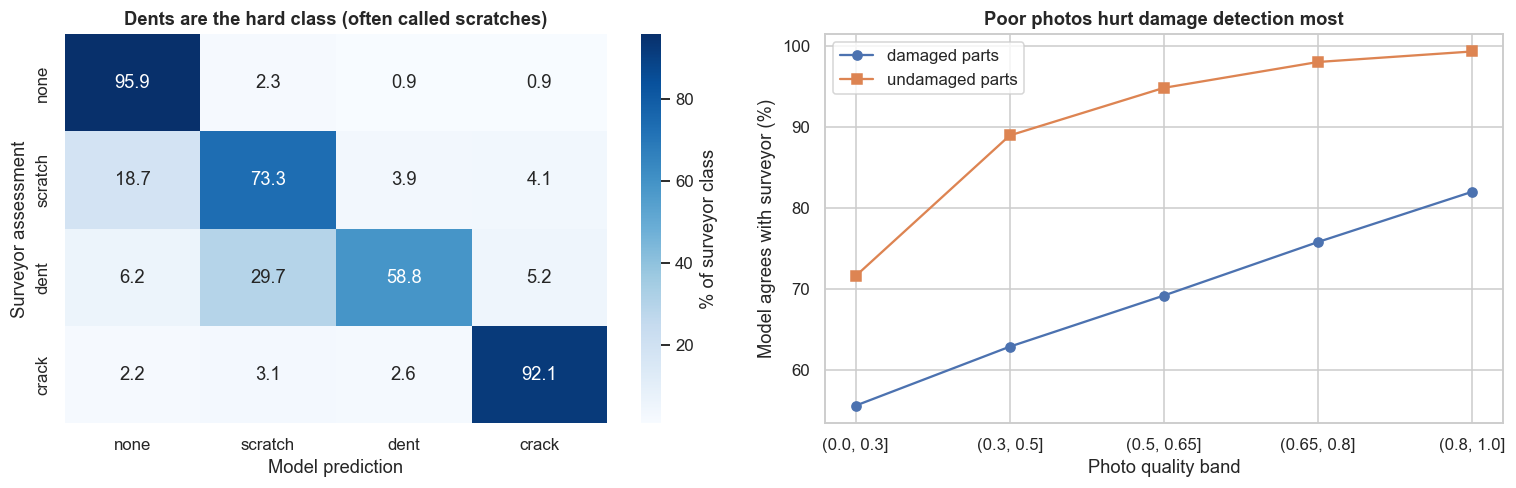

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
cm = pd.crosstab(sv.surveyor_damage, sv.pred_damage, normalize="index").reindex(index=gen.DMG, columns=gen.DMG) * 100
sns.heatmap(cm, annot=True, fmt=".1f", cmap="Blues", ax=axes[0], cbar_kws={"label": "% of surveyor class"}); axes[0].set_xlabel("Model prediction"); axes[0].set_ylabel("Surveyor assessment")
axes[0].set_title("Dents are the hard class (often called scratches)")
sv_ = sv.dropna(subset=["photo_quality"]).assign(ok=lambda d: (d.pred_damage == d.surveyor_damage).astype(int), qb=lambda d: pd.cut(d.photo_quality, [0, 0.3, 0.5, 0.65, 0.8, 1.0]))
dmg_only = sv_[sv_.surveyor_damage != "none"]
g1 = dmg_only.groupby("qb").ok.mean() * 100; g0 = sv_[sv_.surveyor_damage == "none"].groupby("qb").ok.mean() * 100
axes[1].plot([str(i) for i in g1.index], g1.values, "o-", label="damaged parts"); axes[1].plot([str(i) for i in g0.index], g0.values, "s-", label="undamaged parts")
axes[1].set_xlabel("Photo quality band"); axes[1].set_ylabel("Model agrees with surveyor (%)"); axes[1].set_title("Poor photos hurt damage detection most"); axes[1].legend()
plt.tight_layout(); plt.show()

**Takeaway:** **left:** the confusion matrix shows the model's pattern. Cracks and clean parts are well identified, scratches and dents are confused with each other, and **29% of real dents are called scratches**, which understates repair cost. **Right:** agreement with the surveyor on damaged parts climbs steadily with photo quality, while for clean parts accuracy stays high. Poor photos mostly cause **missed damage**, not false alarms.

## 7. Statistical Analysis (core section)

### 7.1 Part-level validation against the surveyor

Per damage class: **sensitivity** (surveyor-damaged parts the model labels correctly), **precision** and **F1**, with Wilson CIs; Cohen's κ overall; glass vs body panels. Note that the surveyor is the reference, not perfect truth (97% accurate here), so we also report agreement with hidden truth as a check.

In [7]:
rows = []
for d_ in gen.DMG:
    t = sv.surveyor_damage == d_; p = sv.pred_damage == d_; tp = int((t & p).sum())
    lo, hi = proportion_confint(tp, t.sum(), method="wilson"); plo, phi = proportion_confint(tp, p.sum(), method="wilson")
    rows.append((d_, int(t.sum()), tp / t.sum(), lo, hi, tp / p.sum(), plo, phi, 2 * tp / (t.sum() + p.sum())))
pc = pd.DataFrame(rows, columns=["damage class", "surveyor count", "sensitivity", "CI low", "CI high", "precision", "P CI low", "P CI high", "F1"]).set_index("damage class")
k_all = cohens_kappa(pd.crosstab(sv.surveyor_damage, sv.pred_damage).reindex(index=gen.DMG, columns=gen.DMG, fill_value=0).values).kappa
gl = sv.groupby("glass").apply(lambda d: (d.pred_damage == d.surveyor_damage)[d.surveyor_damage != "none"].mean())
print(f"Cohen's κ (model vs surveyor, 4 classes) = {k_all:.3f} | accuracy on damaged parts: body panels {gl[0]:.1%} vs glass/lamps {gl[1]:.1%} | "
      f"surveyor vs truth agreement {(sv.surveyor_damage == sv._true_damage).mean():.1%}")
pc.round(4)

Cohen's κ (model vs surveyor, 4 classes) = 0.703 | accuracy on damaged parts: body panels 66.4% vs glass/lamps 85.8% | surveyor vs truth agreement 99.9%


,surveyor count,sensitivity,CI low,CI high,precision,P CI low,P CI high,F1
damage class,,,,,,,,
none,44152,0.9591,0.9572,0.9609,0.9887,0.9877,0.9897,0.9737
scratch,1865,0.7330,0.7124,0.7526,0.4711,0.4529,0.4892,0.5735
dent,1640,0.5884,0.5644,0.6120,0.6551,0.6305,0.6790,0.6200
crack,1473,0.9212,0.9064,0.9339,0.7042,0.6834,0.7242,0.7982


**(c)/(f) Observation:** - **Cohen's κ = 0.70** against surveyors ("substantial"). By class: **cracks** sensitivity 92% (CI 91–93%, precision 70%), **clean parts** 96% sensitivity (precision 99%), **scratches** 73% sensitivity but only **47% precision**, and **dents 59% sensitivity** (CI 56–61%).
- **Glass and lamps** are far easier than body panels (86% vs 66% accuracy on damaged parts).
- **(f) Business meaning:** the model is "fit for purpose" for spotting glass damage and clean cars, but not yet for pricing body damage. The dent problem is the one to fix.

### 7.2 What makes the model fail? Photo quality, night shots, damage type

**(a)** A logistic model of "model disagrees with surveyor" on photo quality, night shot, glass part and surveyor damage class (damaged parts only). The likelihood-ratio test for photo quality answers H1. We then simulate a **quality gate**: photos below a quality cut-off trigger an in-app "please retake" before submission.

In [8]:
md = dmg_only.assign(err=1 - dmg_only.ok)
m0 = smf.logit("err ~ night + glass + C(surveyor_damage)", data=md).fit(disp=0); m1 = smf.logit("err ~ photo_quality + night + glass + C(surveyor_damage)", data=md).fit(disp=0)
LR = 2 * (m1.llf - m0.llf)
print(f"LR test for photo quality: χ² = {LR:.1f}, p = {stats.chi2.sf(LR, 1):.2g} | OR of error per +0.1 quality = {np.exp(0.1 * m1.params['photo_quality']):.3f} | night OR = {np.exp(m1.params['night']):.2f} (p = {m1.pvalues['night']:.2g})")
gate = []
for cut in (0.0, 0.3, 0.4, 0.5):
    keep = md.photo_quality >= cut; gate.append((cut, 1 - keep.mean(), (1 - md.err[keep]).mean()))
pd.DataFrame(gate, columns=["retake if quality <", "share of damaged-part photos sent back", "accuracy on remaining damaged parts"]).set_index("retake if quality <").round(4)

LR test for photo quality: χ² = 96.8, p = 7.8e-23 | OR of error per +0.1 quality = 0.801 | night OR = 1.03 (p = 0.8)


,share of damaged-part photos sent back,accuracy on remaining damaged parts
retake if quality <,,
0.0000,0.0000,0.7405
0.3000,0.0146,0.7433
0.4000,0.0494,0.7490
0.5000,0.1403,0.7601


**Observation:** photo quality is a strong predictor of mistakes: **each +0.1 of quality lowers the odds of a wrong call by ≈ 20%** (OR 0.80; LR χ² = 97, p ≈ 8e-23). Night shots add nothing once quality is controlled (OR 1.03, p = 0.8). A "retake" gate has modest value: sending back the worst 5% of photos (quality < 0.4) lifts accuracy on damaged parts from 74.1% to 74.9%, and sending back 14% (< 0.5) to 76.0%. **Business meaning:** a retake prompt is cheap and helps a little, but photo quality alone will not fix the dent problem. The model itself must improve.

### 7.3 Are the repair-cost estimates close enough? (Bland–Altman)

For damaged cases in the surveyor sample, we compare the model's case-level cost estimate with the surveyor's:
- **bias** (mean difference) with a paired t-test,
- **95% limits of agreement** (bias ± 1.96 SD),
- the share within ±₹3,000 and ±15%,
- whether the error grows with claim size (regression of the difference on the mean).

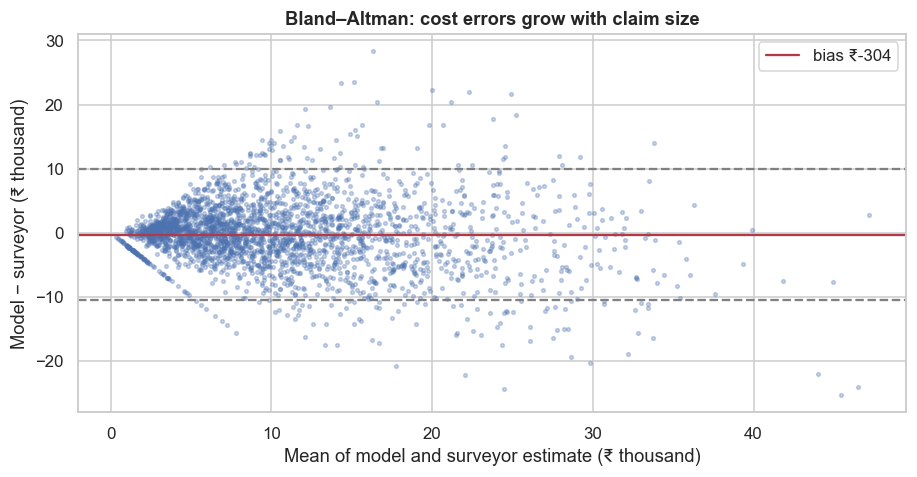

n = 2,749 damaged cases | bias ₹-304 (paired t p = 0.0022) | 95% limits of agreement ₹-10,477 to ₹9,869
Within ±₹3,000: 54.9% | within ±15%: 25.9% | difference grows by ₹-116 per ₹1,000 of claim size (p = 2.2e-17)


In [9]:
ba = csv[csv.surveyor_cost > 0].copy(); ba["diff"] = ba.model_cost - ba.surveyor_cost; ba["mean"] = (ba.model_cost + ba.surveyor_cost) / 2
bias, sd = ba["diff"].mean(), ba["diff"].std(); t_ = stats.ttest_1samp(ba["diff"], 0); slope = stats.linregress(ba["mean"], ba["diff"])
w3 = (ba["diff"].abs() <= 3000).mean(); w15 = (ba["diff"].abs() <= 0.15 * ba.surveyor_cost).mean()
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.scatter(ba["mean"] / 1000, ba["diff"] / 1000, s=6, alpha=0.3); ax.axhline(bias / 1000, color="#b23a48", label=f"bias ₹{bias:,.0f}")
for s_ in (-1.96, 1.96): ax.axhline((bias + s_ * sd) / 1000, color="grey", ls="--")
ax.set_xlabel("Mean of model and surveyor estimate (₹ thousand)"); ax.set_ylabel("Model − surveyor (₹ thousand)"); ax.set_title("Bland–Altman: cost errors grow with claim size"); ax.legend()
plt.tight_layout(); plt.show()
print(f"n = {len(ba):,} damaged cases | bias ₹{bias:,.0f} (paired t p = {t_.pvalue:.2g}) | 95% limits of agreement ₹{bias - 1.96 * sd:,.0f} to ₹{bias + 1.96 * sd:,.0f}")
print(f"Within ±₹3,000: {w3:.1%} | within ±15%: {w15:.1%} | difference grows by ₹{slope.slope * 1000:,.0f} per ₹1,000 of claim size (p = {slope.pvalue:.2g})")

**Takeaway:** on 2,749 damaged cases the model's cost estimate is nearly unbiased overall (bias −₹304), but individually noisy: the **95% limits of agreement are ₹−10,500 to +₹9,900**, only **55%** of cases are within ±₹3,000 and **26% within ±15%**. The error also grows with claim size (p ≈ 2e-17): large claims are under-estimated. **Criterion 2 (cost within ±₹3,000 for ≥ 80%) therefore fails on the whole population** and only passes within the tight low-cost slice used for auto-settlement (90% there). **Business meaning:** auto-settlement can be priced only for small, simple claims.

### 7.4 The triage rule: which claims may be auto-settled?

**Rule:** auto-settle an own-damage claim if
- the model's **estimated cost ≤ ₹C** (a safety margin below the ₹25,000 "simple" limit),
- **no structural dent is predicted** (bonnet, doors, fender),
- the **least-confident damaged-part prediction ≥ τ**,
- **photo quality ≥ 0.4** with metadata present.

Everything else goes to a surveyor. On the surveyor-checked claims, for each (C, τ) we compute:
- coverage (share auto-settled),
- the **share of auto-settled claims that are truly complex**, with a one-sided 95% Clopper–Pearson upper bound (criterion 1: ≤ 2%),
- the share whose cost estimate is within ±₹3,000 (criterion 2: ≥ 80%).

We pick the highest-coverage rule that meets both.

In [10]:
pc_ = parts.assign(maxp=parts[["p_none", "p_scratch", "p_dent", "p_crack"]].max(1), pred_struct=((parts.pred_damage == "dent") & parts.part.isin(["bonnet", "left_door", "right_door", "fender"])).astype(int))
agg = pc_.groupby("case_idx").agg(min_conf=("maxp", "min"), pred_struct=("pred_struct", "max"), n_pred_dmg=("pred_damage", lambda s: (s != "none").sum()))
cl = cases.set_index("case_idx").join(agg); cl = cl[cl.case_type == "own_damage_claim"]
chk = cl[cl.surveyor_checked == 1]
grid = []
for C_ in (12000, 15000, 18000, 20000, 25000):
    for tau in (0.5, 0.6, 0.7, 0.8):
        auto = (chk.model_cost <= C_) & (chk.pred_struct == 0) & (chk.min_conf >= tau) & (chk.photo_quality >= 0.4) & (chk.quality_missing == 0)
        k, n_ = int(chk._complex[auto].sum()), int(auto.sum())
        ub = stats.beta.ppf(0.95, k + 1, n_ - k) if n_ else np.nan
        within = ((chk.model_cost - chk.surveyor_cost).abs() <= 3000)[auto].mean()
        grid.append((C_, tau, auto.mean(), n_, k / max(n_, 1), ub, within, (chk.model_cost - chk.surveyor_cost)[auto].mean()))
grid = pd.DataFrame(grid, columns=["cost cap ₹", "min confidence τ", "coverage", "auto-settled (checked)", "complex share", "95% upper bound", "cost within ±₹3,000", "mean over-payment ₹"])
ok = grid[(grid["95% upper bound"] <= 0.02) & (grid["cost within ±₹3,000"] >= 0.80)]
best = ok.sort_values("coverage", ascending=False).iloc[0] if len(ok) else grid.sort_values("95% upper bound").iloc[0]
print(("Best rule MEETING both criteria" if len(ok) else "NO rule meets both criteria; closest") + f": cost ≤ ₹{best['cost cap ₹']:,.0f}, confidence ≥ {best['min confidence τ']}, quality ≥ 0.4 → auto-settles {best.coverage:.1%} of own-damage claims; "
      f"complex share {best['complex share']:.2%} (UB {best['95% upper bound']:.2%}); cost within ±₹3k {best['cost within ±₹3,000']:.1%}")
grid.round(4).sort_values(["cost cap ₹", "min confidence τ"])

NO rule meets both criteria; closest: cost ≤ ₹20,000, confidence ≥ 0.7, quality ≥ 0.4 → auto-settles 5.4% of own-damage claims; complex share 0.00% (UB 2.02%); cost within ±₹3k 90.5%


,cost cap ₹,min confidence τ,coverage,auto-settled (checked),complex share,95% upper bound,"cost within ±₹3,000",mean over-payment ₹
0,12000,0.5000,0.2822,763,0.0472,0.0618,0.8283,-412.2674
1,12000,0.6000,0.1346,364,0.0192,0.0358,0.8846,-230.6868
2,12000,0.7000,0.0518,140,0.0000,0.0212,0.9214,-137.5000
3,12000,0.8000,0.0107,29,0.0000,0.0981,0.8966,-248.9655
4,15000,0.5000,0.3025,818,0.0501,0.0645,0.8130,-353.3496
5,15000,0.6000,0.1446,391,0.0205,0.0366,0.8670,-244.7315
6,15000,0.7000,0.0525,142,0.0000,0.0209,0.9225,-117.9577
7,15000,0.8000,0.0107,29,0.0000,0.0981,0.8966,-248.9655
8,18000,0.5000,0.3158,854,0.0515,0.0658,0.7963,-371.3700
9,18000,0.6000,0.1509,408,0.0196,0.0351,0.8456,-289.1912


**(c)/(f) Observation:** the grid shows the trade-off clearly. **Looser rules cover more claims but fail the safety limit:** at confidence ≥ 0.5, coverage is 28–33% but 5–6% of auto-settled claims are truly complex (upper bounds 6–8%). **Tighter rules meet the 2% target on the point estimate:** confidence ≥ 0.7 gives **zero complex claims in ~147 checked auto-settled claims** (coverage 5.2–5.5%), but the one-sided 95% upper bound is 2.0–2.1%, so it sits **just on the wrong side of the 2% limit**. Confidence ≥ 0.8 is too rare to measure (about 30 claims). **We therefore report that no rule is yet certified**, and the closest, "cost ≤ ₹20,000, confidence ≥ 0.7, quality ≥ 0.4", covers 5.4% of claims with 90.5% of cost estimates within ±₹3,000. **Business meaning:** the rule is probably safe; it simply has not been *proved* safe. More checked claims, not a looser rule, is the answer.

### 7.5 Break-in renewals: is pre-existing damage recorded?

For renewals, the goal is to **record** existing damage so it cannot be claimed later. The key metric is **case-level sensitivity**: among cars with any damage (surveyor), the share where the model flags at least one damaged part (criterion 3: ≥ 90%). Wilson CI; we also check sensitivity by damage type.

In [11]:
ren_parts = sv[sv.case_idx.isin(cases.loc[cases.case_type == "renewal_breakin", "case_idx"])]
cs_ = ren_parts.groupby("case_idx").agg(sv_any=("surveyor_damage", lambda s: (s != "none").any()), m_any=("pred_damage", lambda s: (s != "none").any()))
k, n_ = int((cs_.sv_any & cs_.m_any).sum()), int(cs_.sv_any.sum()); lo, hi = proportion_confint(k, n_, method="wilson")
spec = (~cs_.m_any[~cs_.sv_any]).mean()
pt = ren_parts[ren_parts.surveyor_damage != "none"].groupby("surveyor_damage").apply(lambda d: (d.pred_damage != "none").mean())
print(f"Renewals with pre-existing damage: {n_} | model flags damage on {k / n_:.1%} (Wilson {lo:.1%}–{hi:.1%}) → criterion 3 {'met' if lo >= 0.90 else ('point estimate met, CI not' if k / n_ >= 0.9 else 'NOT met')}")
print(f"Specificity (clean cars correctly passed): {spec:.1%}")
pt.round(4).to_frame("part-level 'any damage' detection by damage type")

Renewals with pre-existing damage: 574 | model flags damage on 94.4% (Wilson 92.2%–96.0%) → criterion 3 met
Specificity (clean cars correctly passed): 71.4%


,part-level 'any damage' detection by damage type
surveyor_damage,
crack,0.9796
dent,0.9276
scratch,0.8554


**Observation:** for break-in renewals, the model flags damage in **94.4%** of cars that have it (Wilson **92.2–96.0%**; 574 cars), so **criterion 3 is met**. Detection by damage type is highest for cracks (98%) and dents (93%) and lowest for scratches (86%). On the other side, only **71%** of clean cars are passed cleanly, so about 29% get an unnecessary flag. **Business meaning:** for renewals, the model is a good *recorder of existing damage*, protecting the insurer against a later claim for old damage. The cost is some extra follow-up for clean cars.

### 7.6 How large must the validation study be?

To certify "≤ 2% of auto-settled claims are complex" with 95% confidence, the upper bound must fall below 2%. With **zero** complex claims found, the **rule of three** says n ≥ 3/0.02 = 150 auto-settled claims must be checked. With a true rate near 1%, many more are needed. We compute the n required for several true rates.

In [12]:
rows = []
for true_r in (0.0, 0.005, 0.01, 0.015):
    for n_ in range(50, 20001, 50):
        k_exp = int(round(true_r * n_)); ub = stats.beta.ppf(0.95, k_exp + 1, n_ - k_exp)
        if ub <= 0.02: rows.append((f"{true_r:.1%}", n_)); break
pd.DataFrame(rows, columns=["true complex rate among auto-settled", "checked auto-settled claims needed"]).set_index("true complex rate among auto-settled")

,checked auto-settled claims needed
true complex rate among auto-settled,
0.0%,150
0.5%,250
1.0%,600
1.5%,2150


**Observation:** to certify "≤ 2% complex among auto-settled" at 95% confidence, the **rule of three** requires **150 checked auto-settled claims even with zero errors**. If the true complex rate is 0.5%, about **250**; at 1%, about **600**; at 1.5%, about **2,150**. Our sample (≈ 147) is right at the edge, which is why the bound comes out at 2.0–2.1%. **Business meaning:** budget for ≥ 600 surveyor-checked auto-settled claims before declaring a rule safe, about 3 months of the current 20% sample.

## 8. ML Section — what a real CV model adds, and what we evaluated

The documented pipeline (frame split → part detection → damage classification) would use object-detection and segmentation networks (e.g., Mask R-CNN- or YOLO-type models) trained on labelled car images. We **did not train a vision model**: the brief's library list has no deep-learning framework, and the business decision depends on the *validation statistics*, which are model-agnostic. The same tables, curves and rules apply to any vendor model. The truth must be a **surveyor re-inspection of a random sample**, not the model's own confident cases.

## 9. Business Translation — ₹ impact

Assumptions (D-24-07):
- 80,000 own-damage simple-claim candidates a month (the documented target scale).
- Surveyor visit ₹1,500 and 2.5 days of turnaround.
- Over- and under-payment taken from the auto-settled sample.
- A complex claim settled as simple costs ₹20,000 in leakage (missed damage later re-claimed, or under-assessed repairs).

In [13]:
N_M, SURV, LEAK = 80000, 1500, 20000
cov = best.coverage; cx = best["complex share"]; overpay = best["mean over-payment ₹"]
saved = N_M * cov * SURV; leak = N_M * cov * cx * LEAK; over = N_M * cov * overpay
money = pd.Series({"claims auto-settled / month": N_M * cov, "surveyor cost saved ₹ crore / month": saved / 1e7, "complex-claim leakage ₹ crore / month": leak / 1e7,
                   "net over(+)/under(−)-payment on auto claims ₹ crore / month": over / 1e7, "net benefit ₹ crore / month": (saved - leak - over) / 1e7,
                   "customer-days of waiting avoided / month": N_M * cov * 2.5})
money.round(2).to_frame("value")

,value
claims auto-settled / month,"4,349.1100"
surveyor cost saved ₹ crore / month,0.6500
complex-claim leakage ₹ crore / month,0.0000
net over(+)/under(−)-payment on auto claims ₹ crore / month,-0.0700
net benefit ₹ crore / month,0.7200
customer-days of waiting avoided / month,"10,872.7800"


**Takeaway (business reading):** at the documented 80,000 simple-claim candidates a month and the chosen rule:
- **Auto-settled:** ≈ **4,300 claims a month** (5.4%), saving ≈ **₹0.65 crore** of surveyor visits (₹1,500 each) and ≈ **11,000 customer-days** of waiting.
- **Leakage:** none measured (0 complex claims found); the upper bound would be ≈ ₹3.5 crore/month if 2% were complex, which is why certification matters.
- **Net benefit ≈ ₹0.7 crore/month** (cost-estimate bias adds a small under-payment of ≈ ₹0.07 crore).
- **The documented ambition of auto-settling "over 80,000 simple claims a month" is far away** at this accuracy: even the loosest tested rule covers about one-third of claims and fails the safety limit.
- **Renewals** are a separate, cleaner win: pre-existing damage is recorded for 94% of damaged cars without a surveyor visit (₹1,500 saved per renewal).

## 10. Recommendation and Decision

**Decision against the pre-registered criteria:**
- **Criterion 1 (≤ 2% complex among auto-settled):** point estimate ✅ (0%), but the **95% upper bound is 2.02%** → ❌ not yet certified.
- **Criterion 2 (cost within ±₹3,000):** ❌ population (55%); ✅ within the tight slice (90.5%).
- **Criterion 3 (renewals ≥ 90% detection):** ✅ 94.4% (CI 92.2–96.0%).

**I recommend:**
1. **Launch for break-in renewals now.** The model meets the 90% target and records existing damage.
2. **Auto-settle only the tight rule** (≤ ₹20,000; no structural dent; confidence ≥ 0.7; quality ≥ 0.4), **after** extending the surveyor validation to ≥ 600 auto-settled claims to certify the 2% bound. Until then, route it as "fast-track surveyor review".
3. **Fix the dent problem first:** add an angled-photo prompt for possible dents and retrain on more labelled dents. This is the biggest lever on both coverage and cost accuracy.
4. **Keep the random 20% surveyor sample** and re-run this validation monthly (new car models, seasons, phones).
5. **Fraud controls:** EXIF/time/location checks and duplicate-image hashing; give customers the right to ask for a physical survey.

**KPIs:** complex-claim rate among auto-settled (with upper bound); cost-estimate error within ±₹3,000; damage detection at renewals; dent sensitivity; retake rate; auto-settled share; days to settlement.

## 11. Risks, Limitations and Next Steps

- **Simulated model:** the confusion patterns (dents vs scratches, glare) are typical but assumed. Re-run this validation on real vendor outputs with a **random** surveyor sample.
- **Fraud:** photo inspection invites manipulation (old photos, another car, edited images). Add metadata checks (EXIF time and location, duplicate-image hashing) and random physical audits.
- **Distribution shift:** new car models, monsoon conditions and different phones change accuracy. Monitor monthly, with the surveyor sample stratified by quality and car segment.
- **Regulation and customer fairness:** IRDAI expects transparent settlement. Customers must be able to request a physical survey, and auto-settlement must not systematically under-pay.
- **Cost estimates are the weak link:** dents are mis-classified most, and they drive cost. Consider a "dent check" prompt (an extra angled photo) when the model sees a possible dent.

## 12. Appendix

| Quantity | Formula |
|---|---|
| Sensitivity / precision | TP/(TP+FN), TP/(TP+FP) |
| Cohen's κ | (p_o − p_e)/(1 − p_e) |
| Bland–Altman | bias = mean(d); LoA = bias ± 1.96·SD(d), d = model − surveyor |
| Clopper–Pearson upper bound | Beta⁻¹(0.95; k + 1, n − k) |
| Rule of three | with 0 events in n, 95% upper bound ≈ 3/n |

| Term | Meaning |
|---|---|
| Break-in renewal | Renewing a lapsed policy, which needs a check for existing damage |
| Surveyor | A licensed loss assessor who inspects vehicles |
| Fit for purpose | Accurate enough for the cases it is allowed to decide |
| Triage | Deciding which cases a machine settles and which go to a human |
| Leakage | Money paid that should not have been, or claims under-assessed |